In [1]:
import torch
import torchvision
import numpy as np
import pandas as pd
from torch import nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

In [2]:
def load_images(path):
    with open(path, "rb") as f:
        magic, n, rows, cols = np.frombuffer(f.read(16), dtype=">i4")
        assert magic == 2051
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows, cols)

def load_labels(path):
    with open(path, "rb") as f:
        magic, n = np.frombuffer(f.read(8), dtype=">i4")
        assert magic == 2049
        return np.frombuffer(f.read(), dtype=np.uint8)

root = "data/MNIST/raw/"
X_train = load_images(root + "train-images-idx3-ubyte")

In [3]:
X_train = (X_train[:, ::1, ::1] > 127).astype(np.float32)
X = X_train.reshape(X_train.shape[0], -1)

In [4]:
X = X[:1000]

In [5]:
train_samples = []
train_targets =[]
for d in range(X.shape[1]):

    # masking the input first
    mask = np.zeros_like(X, dtype=X.dtype)
    mask[:, :d] = 1
    masked_input = X * mask
    masked_input = torch.from_numpy(masked_input)

    # preparing the position for appending to the input
    position = np.array([d // 28, d % 28], dtype=np.float32) / 28.0
    # (1000, 2), every row [1/14, 6/14]
    position = torch.from_numpy(np.tile(position, (X.shape[0], 1)))

    # appending
    final_input = torch.cat((masked_input, position), dim=-1)
    
    train_samples.append(final_input)
    train_targets.append(X[:, d])

train_samples = np.array(train_samples)
train_samples = train_samples.reshape(-1, train_samples.shape[-1])

train_targets = np.array(train_targets).reshape(-1)

In [6]:
X_tensor = torch.from_numpy(train_samples)
y_tensor = torch.from_numpy(train_targets)


print(X_tensor.shape)
print(y_tensor.shape)

torch.Size([784000, 786])
torch.Size([784000])


In [7]:
class Network(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.input_size = input_size
        self.net = nn.Sequential(
            nn.Linear(self.input_size, 512),
            nn.LeakyReLU(),
            # nn.BatchNorm1d(512),
            nn.Linear(512, 1024),
            nn.LeakyReLU(),
            # nn.BatchNorm1d(1024),
            nn.Linear(1024, 512),
            nn.LeakyReLU(),
            # nn.BatchNorm1d(512),
            nn.Linear(512, 2),
        )
        
    def forward(self, x):
        batch_size = x.shape[0]
        return self.net(x)

In [8]:
net = Network(input_size=28*28 + 2)

In [9]:
class Dataset(torch.utils.data.Dataset):

    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [10]:


device = 'cuda' if torch.cuda.is_available() else 'cpu'

loader = DataLoader(TensorDataset(X_tensor, y_tensor),
                    batch_size=256, shuffle=True)

net = Network(input_size=28*28 + 2).to(device)
optimizer = torch.optim.Adam(net.parameters(), lr=5e-4, weight_decay=0.0001)

for epoch in range(10):
    net.train()
    running = 0.0

    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()

        mu, log_sigma = net(xb).chunk(2, dim=-1)
        sigma = log_sigma.clamp(-2, 2).exp()

        dist = torch.distributions.Normal(mu.squeeze(-1), sigma.squeeze(-1))
        loss = -dist.log_prob(yb).mean()

        loss.backward()
        optimizer.step()
        running += loss.item() * xb.shape[0]

    print(f"epoch {epoch+1}:  {running / len(y_tensor):.4f}")

epoch 1:  -0.1533
epoch 2:  -0.4575
epoch 3:  -0.5211
epoch 4:  -0.5634
epoch 5:  -0.5899
epoch 6:  -0.6127
epoch 7:  -0.6291
epoch 8:  -0.6380
epoch 9:  -0.6490
epoch 10:  -0.6606


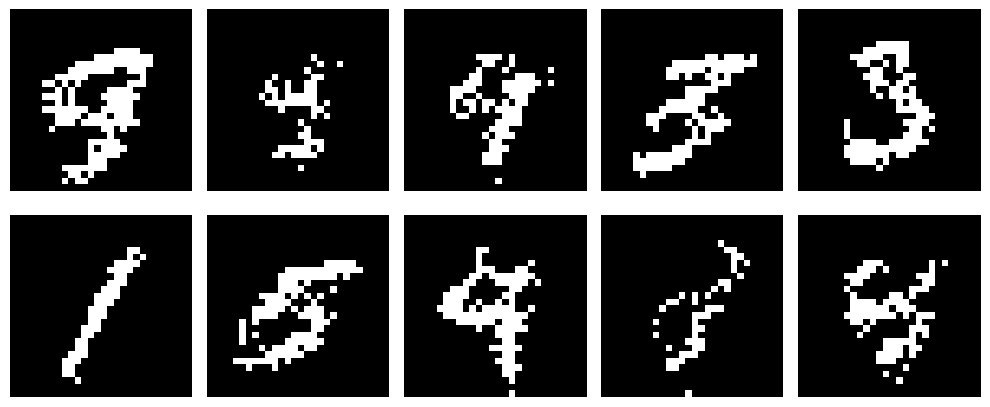

In [14]:
@torch.no_grad()
def sample_image(net, n_pix=784):
    net.eval()
    context = torch.zeros(1, n_pix, device=device)

    for d in range(n_pix):
        pos = torch.tensor([[d // 28, d % 28]],
                           dtype=torch.float32, device=device) / 28.0
        inp = torch.cat([context, pos], dim=1)

        mu, log_sigma = net(inp).chunk(2, dim=-1)
        sigma = log_sigma.clamp(-2, 2).exp()

        pixel = mu + sigma * torch.randn_like(mu)
        context[0, d] = float(pixel.item() > 0.5)

    return context.reshape(28, 28).cpu().numpy()


fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax in axes.flat:
    ax.imshow(sample_image(net), cmap='gray')
    ax.axis('off')
plt.tight_layout(); plt.show()

In [12]:
# explanation: 

# there is a difference bw fitting a gaussian on this data vs using a NN to predict a gaussian to fit that data
# the only-gaussian approach would end up giving us the average of the (say) 11th pixel after first 10 pixels 1-10 are used as input
# the gaussian would try to fit the 11th pixel value for all images in the dataset, and hence would end up giving / predicting the AVERAGE value of all
# the pixels at the 11th position


# the NN method works, since, when it predicts a gaussian for the 11th pixel, it predicts a new gaussain for EACH 11TH PIXEL IN EACH NEW IMAGE
# earlier example would use thee same gaussian for all 11th pixels for all images, NN predicted gauussain fits a new gaussian for every 11th pixel 
# in every separate immage. so thte 11th pixel in a 3 aand the 11th pixel in a 7 would be according to the previously generated pixels of the 3 and the 7
# respectively, as opposed to geneerating an 11th pixeel value as just the aveerage of the 3 and the 7